# Introduction

Customer Behaviour and it’s prediction lies 
at the core of every Business Model. From 
Stock Exchange, e-Commerce and 
Automobile to even Presidential Elections, 
predictions serve a great purpose. Most of 
these predictions are based on the data 
available about a person’s activity either 
online or in-person.

## Problem Statement

For the purpose of this Project we will be creating one such Recommendation Engine 
from the ground-up, where every single user, based on there area of interest and ratings, 
would be recommended a list of movies that are best suited for them.


## Dataset Information

1. **ID** –Contains the separate keys for  customer and movies. 
2. **Rating** – A section contains the user ratings for all the movies.
3. **Genre** –Highlights the category of the 
4. **Movie Name** –Name of the movie with respect to the movie id.

## Steps We will take

In this notebook, we will follow a structured approach to wrangle the movie datasets. The steps include:

1. **Data Gathering**: Import necessary libraries (pandas, numpy) and load the datasets.
2. **Data Assessing & Cleaning**: Manually export for review and programmatically check structure, missing values, duplicates, and statistics.
3. **Validation and Merging**: Re-check the cleaned data.
4. **Exploratory Data Analysis**: Finding the hidden patter inside data distribution.
5. **Model fitting**: fit the data on the best suited model.
6. **Model Evaluation & validation**: check the model accuracy and performance on varius metric
7. **Model Deployement**: Simple flask app to check the model performance

### Data Gathering:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
from pathlib import Path

# Split only on the first two commas; remaining commas belong to the movie title.
rows = []
with Path('movie_titles.csv').open(encoding='ISO-8859-1', newline='') as file:
    for line in file:
        fields = line.rstrip('\r\n').split(',', 2)
        if len(fields) == 3:
            rows.append(fields)

df_movies = pd.DataFrame(rows, columns=['movie_id', 'year', 'movie_name'])
df_movies['movie_id'] = pd.to_numeric(df_movies['movie_id'], errors='coerce')
df_movies['year'] = pd.to_numeric(df_movies['year'], errors='coerce')

df_movies.tail()

,movie_id,year,movie_name
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...
17766,17767,2004.0,Fidel Castro: American Experience
17767,17768,2000.0,Epoch
17768,17769,2003.0,The Company
17769,17770,2003.0,Alien Hunter


**Note:**  
- There is a Data importing issue in raw data, since there are movies with comma. Hence `movie_name` col is fixed.

In [4]:
netflix_df = pd.read_csv('combinedNetflixData.txt', header=None, sep = '\t')

In [5]:
netflix_df.head()

,0
0,1:
1,"1488844,3,2005-09-06"
2,"822109,5,2005-05-13"
3,"885013,4,2005-10-19"
4,"30878,4,2005-12-26"


In [6]:
netflix_df.rename(columns={0: 'customer_id'}, inplace=True)

In [7]:
mask = netflix_df['customer_id'].astype(str).str.match(r"^\d+:$")

In [8]:
# Extract movie ID from those rows
netflix_df["movie_id"] = netflix_df["customer_id"].where(mask).str.replace(":", "", regex=False)

In [9]:
netflix_df.head()

,customer_id,movie_id
0,1:,1
1,"1488844,3,2005-09-06",NaN
2,"822109,5,2005-05-13",NaN
3,"885013,4,2005-10-19",NaN
4,"30878,4,2005-12-26",NaN


In [10]:
# Propagate movie ID to subsequent rows
netflix_df["movie_id"] = netflix_df["movie_id"].ffill()

# Remove the movie-header rows
netflix_df = netflix_df[~mask].copy()

In [11]:
# Convert columns to numeric types
netflix_df["movie_id"] = netflix_df["movie_id"].astype(int)
print(netflix_df)

                   customer_id  movie_id
1         1488844,3,2005-09-06         1
2          822109,5,2005-05-13         1
3          885013,4,2005-10-19         1
4           30878,4,2005-12-26         1
5          823519,3,2004-05-03         1
...                        ...       ...
24058258  2591364,2,2005-02-16      4499
24058259  1791000,2,2005-02-10      4499
24058260   512536,5,2005-07-27      4499
24058261   988963,3,2005-12-20      4499
24058262  1704416,3,2004-06-02      4499

[24053764 rows x 2 columns]


In [12]:
netflix_df[["customer_id", "rating", "date"]] = (
    netflix_df["customer_id"].str.split(",", expand=True)
)

netflix_df["customer_id"] = netflix_df["customer_id"].astype(int)
netflix_df["rating"] = netflix_df["rating"].astype(int)
netflix_df["date"] = pd.to_datetime(netflix_df["date"])

KeyboardInterrupt: 

In [ ]:
netflix_df['rating'] = pd.to_numeric(netflix_df['rating'], errors='coerce')

In [ ]:
netflix_df.drop(columns=['date'], inplace=True)

**Note**
- 'CombinedNetflixData.txt' has messy data problem. 'movie_id' has been seperated.
- 'Date' column has been removed from since we are dealing with tabular data.

### Data Assessing & Cleaning

- Over Here we are going to perform two type of Data assessing.
1. Mannual Assessing (using Excel)
2. Programatic Assessing (using Pandas or numpy)

- Afterwards we will write all the issues, in order to clean our data.


In [ ]:
netflix_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 3 columns):
 #   Column       Dtype
---  ------       -----
 0   customer_id  int64
 1   movie_id     int64
 2   rating       int64
dtypes: int64(3)
memory usage: 734.1 MB


In [ ]:
netflix_df.shape

(24053764, 3)

In [ ]:
netflix_df['movie_id'].unique().shape

(4499,)

In [ ]:
df_movies['movie_id'].unique().shape

(17770,)

#### Issues with the dataset found

**Data - `movie_titles.csv`**

- **validity issue**: Some movies are having with comma which creating issue. Excel and pandas considering it as new column. Hence importing only 1st column.
- **validity issue**: Some movies name have speacial charecters, need to remove before apply ml.
- **completion issues**: multiple movies has `year` missing. since null is less than 10, need manual filling.
- **validity issue**: Column are in diffrent format.



**Data - `combinedNetflixData.txt`**

- **Messy Data**: Movie id are given in the first row followed by customer_id, rating and date.
- **validity issue**: columns are found in string format.
- **completion issue**: There is only 4499 movies rating available out of total 17770 movies.




In [ ]:
#**validity issue**: Some movies name have speacial charecters, need to remove before 
df_movies['movie_name'] = df_movies['movie_name'].str.replace(r'[\W_]', '', regex=True)

In [ ]:
mask = df_movies['year'].isnull()

In [ ]:
df_movies[mask]

,movie_id,year,movie_name
4387,4388,NaN,AncientCivilizationsRomeandPompeii
4793,4794,NaN,AncientCivilizationsLandofthePharaohs
7240,7241,NaN,AncientCivilizationsAthensandGreece
10781,10782,NaN,RotiKapadaAurMakaan
15917,15918,NaN,HoteHotePyaarHoGaya
16677,16678,NaN,JimmyHollywood
17666,17667,NaN,ErosDanceDhamaka


In [ ]:
indexing = df_movies[mask].index

In [ ]:
df_movies.loc[indexing, 'year'] = ['2001', '1995', '2001', '1974', '1999', '1994', '2022' ]

C:\Users\shubh\AppData\Local\Temp\ipykernel_30516\91213435.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['2001', '1995', '2001', '1974', '1999', '1994', '2022']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_movies.loc[indexing, 'year'] = ['2001', '1995', '2001', '1974', '1999', '1994', '2022' ]


In [ ]:
df_movies.loc[indexing, 'year']

4387     2001
4793     1995
7240     2001
10781    1974
15917    1999
16677    1994
17666    2022
Name: year, dtype: object

In [ ]:
df_movies['year'] = df_movies['year'].astype(int)

In [ ]:
df_movies['year'].value_counts()

year
2004    1436
2002    1310
2003    1271
2000    1234
2001    1186
        ... 
1923       2
1914       2
1909       1
1896       1
2022       1
Name: count, Length: 95, dtype: int64

In [ ]:
df_movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17770 entries, 0 to 17769
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   movie_id    17770 non-null  int64 
 1   year        17770 non-null  int64 
 2   movie_name  17770 non-null  object
dtypes: int64(2), object(1)
memory usage: 416.6+ KB


### Validation and Merging

In [ ]:
#Since the both dataframe are ready, we can merge them to get the final dataset for analysis. 
# We will use inner join to get the common records from both the dataframes.

df = pd.merge(df_movies, netflix_df, how='inner', on='movie_id')


In [2]:
df.info()

NameError: name 'df' is not defined

In [ ]:
df.columns = df.columns.str.strip()

### Export Clean Data

In [ ]:
df.to_csv('final_dataset.csv', index=False)

### Exploratory Data Analysis

In [ ]:
import gdown
import pandas as pd

# Pass the original Google Drive link directly to gdown using the 'id' parameter
file_id = "1MnAtxxrwBVsq42IlcovplT_w_MAlIuU1"

# We pass the ID directly into gdown instead of building a URL string manually
output_filename = "dataset.csv"
gdown.download(id=file_id, output=output_filename, quiet=False)

# Read the downloaded data into Pandas
df = pd.read_csv(output_filename)
print("Data successfully loaded!")
print(df.head())



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('final_dataset.csv')


df.head(3)

,movie_id,year,movie_name,customer_id,rating
0,1,2003,DinosaurPlanet,1488844,3
1,1,2003,DinosaurPlanet,822109,5
2,1,2003,DinosaurPlanet,885013,4


In [4]:
# import the libraries
import plotly.graph_objects as go


movies_per_year = df['year'].value_counts().sort_index()

trace1 = go.Bar(x=movies_per_year.index, y=movies_per_year.values, name='Movies per Year')

layout = go.Layout(title='Number of Movie Releases by Year', xaxis={'title': 'Year'}, yaxis={'title': 'Number of Movies'})

fig = go.Figure(data=[trace1], layout=layout)

fig.show()

In [3]:
customer_counts = df['customer_id'].value_counts().sort_index(ascending=False)

In [4]:
customer_counts = customer_counts.sort_values(ascending=False)

In [5]:
customer_counts

customer_id
305344     4467
387418     4422
2439493    4195
1664010    4019
2118461    3769
           ... 
1816220       1
1816093       1
1018895       1
1628011       1
280814        1
Name: count, Length: 470758, dtype: int64

In [6]:
customer_counts.describe()

count    470758.000000
mean         51.095816
std          74.405055
min           1.000000
25%           8.000000
50%          24.000000
75%          64.000000
max        4467.000000
Name: count, dtype: float64

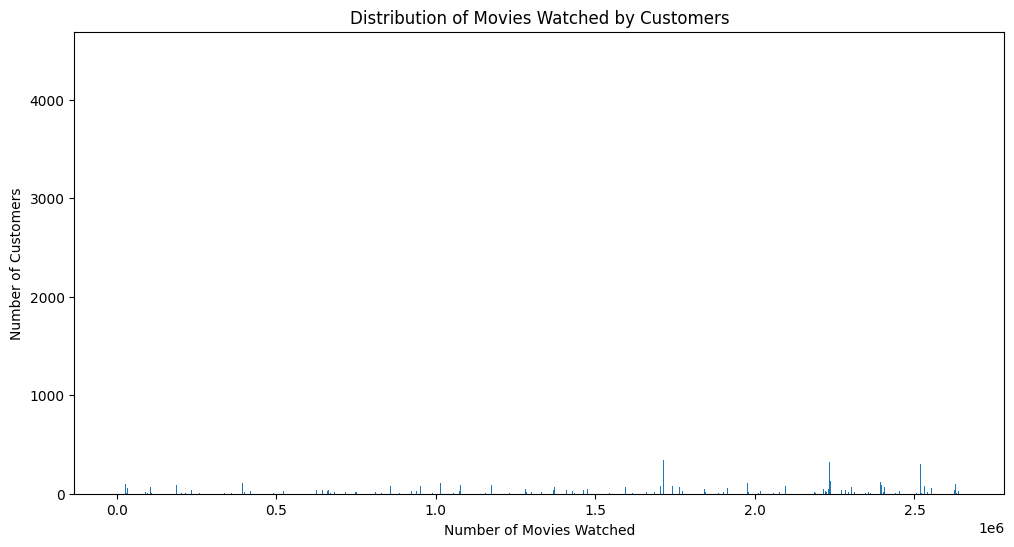

In [9]:
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 6))
plt.bar(
    customer_counts.index,
    customer_counts.values
)
plt.title('Distribution of Movies Watched by Customers')
plt.xlabel('Number of Movies Watched')
plt.ylabel('Number of Customers')
plt.show()

In [7]:
df.groupby('rating')['rating'].agg(['count'])

,count
rating,
1,1118186
2,2439073
3,6904181
4,8085741
5,5506583


In [8]:
counts_mean = customer_counts.mean()
counts_std = customer_counts.std()

customer_z_scores = (customer_counts - counts_mean) / counts_std

customers_above_2sd = customer_z_scores[customer_z_scores > 2]
customers_below_2sd = customer_z_scores[customer_z_scores < -2]

print("Customers above +2 SD:", len(customers_above_2sd))
print("Customers below -2 SD:", len(customers_below_2sd))

Customers above +2 SD: 21045
Customers below -2 SD: 0


In [9]:
#check who all are the customers above +2 SD and below -2 SD

inactive_cus_mask = customers_above_2sd.index.tolist()


In [10]:
df_filtered = df[~df['customer_id'].isin(inactive_cus_mask)]

In [11]:
df_filtered.drop(columns=['movie_name'], inplace=True)

C:\Users\shubh\AppData\Local\Temp\ipykernel_34588\1992337323.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered.drop(columns=['movie_name'], inplace=True)


In [12]:
df_filtered.isnull().sum()

movie_id       0
year           0
customer_id    0
rating         0
dtype: int64

#### Observation

- highest movie was released 2004, in our data. 
- 'Distribution of Movies Watched by Customers' chart shows maximum people has less review, however someone has highest review of 4467
- Highest people had given 4 star rating.
- Since there are skewness in 'Distribution of Movies Watched by Customers', so it suggest very few people are regular active and watch movie. we need to remove those inactive customer from data.




### Model fitting

In [15]:
!pip install scikit-surprise

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 7.8 MB/s  0:00:00



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from surprise import Dataset, Reader, SVD
from surprise.model_selection import cross_validate

In [14]:
# SVD uses customer/movie IDs and ratings; year is not used as a feature.
ratings = df_filtered[['customer_id', 'movie_id', 'rating']]

In [15]:
# Validate the columns and rating scale expected by Surprise.
assert not ratings.isnull().any().any(), "Ratings data contains missing values."
assert ratings['rating'].between(1, 5).all(), "Ratings must be between 1 and 5."

print("Rows:", len(ratings))
print("Unique customers:", ratings['customer_id'].nunique())
print("Unique movies:", ratings['movie_id'].nunique())
print("Rating values:", sorted(ratings['rating'].unique()))
print("Customer/movie IDs are categorical identifiers; Surprise encodes them internally.")

Rows: 17743396
Unique customers: 449713
Unique movies: 4499
Rating values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Customer/movie IDs are categorical identifiers; Surprise encodes them internally.


In [16]:
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(ratings, reader)

svd_model = SVD(random_state=42)

### Model Evaluation & validation

In [ ]:
cv_results = cross_validate(
    svd_model,
    data,
    measures=["RMSE", "MAE"],
    cv=10,
    verbose=True
)

print(f"Mean CV RMSE: {cv_results['test_rmse'].mean():.4f}")
print(f"Mean CV MAE:  {cv_results['test_mae'].mean():.4f}")

best_model = SVD(random_state=42)
best_model.fit(data.build_full_trainset())

In [ ]:
evaluation = pd.DataFrame({
    "Fold": range(1, len(cv_results["test_rmse"]) + 1),
    "RMSE": cv_results["test_rmse"],
    "MAE": cv_results["test_mae"]
})

display(evaluation)

print(f"Mean RMSE: {evaluation['RMSE'].mean():.4f} ± {evaluation['RMSE'].std():.4f}")
print(f"Mean MAE:  {evaluation['MAE'].mean():.4f} ± {evaluation['MAE'].std():.4f}")

evaluation.set_index("Fold")[["RMSE", "MAE"]].plot(
    kind="bar", figsize=(8, 4), rot=0,
    title="SVD Cross-Validation Metrics by Fold"
)
plt.ylabel("Error (lower is better)")
plt.tight_layout()
plt.show()

In [19]:
# Train the requested model on the complete dataset.
trainset = data.build_full_trainset()
svd_model.fit(trainset)

def recommend_movies(customer_id, n=5):
    watched_movie_ids = set(
        ratings.loc[
            ratings['customer_id'].eq(customer_id),
            'movie_id'
        ].astype(int)
    )

    candidate_movies = df_movies[
        df_movies['movie_id'].isin(ratings['movie_id'].unique())
        & ~df_movies['movie_id'].isin(watched_movie_ids)
    ][['movie_id', 'movie_name']].drop_duplicates()

    predictions = [
        (
            row.movie_id,
            row.movie_name,
            svd_model.predict(customer_id, row.movie_id).est
        )
        for row in candidate_movies.itertuples(index=False)
    ]

    recommendations = sorted(
        predictions,
        key=lambda item: item[2],
        reverse=True
    )[:n]

    print(f"\nTop {n} recommendations for customer {customer_id}:")
    for rank, (_, movie_name, rating) in enumerate(recommendations, start=1):
        print(f"{rank}. {movie_name} — predicted rating: {rating:.3f}")

    return recommendations




In [23]:
# Select a valid customer and display their recommendations.
example_customer_id = int(ratings['customer_id'].iloc[10])
top_recommendations = recommend_movies(example_customer_id, n=5)


Top 5 recommendations for customer 2442:
1. Dil Chahta Hai — predicted rating: 5.000
2. The L Word: Season 2 — predicted rating: 4.837
3. Little House on the Prairie: Season 3 — predicted rating: 4.825
4. As Time Goes By: Series 8 — predicted rating: 4.682
5. Midsomer Murders: Ring Out Your Dead — predicted rating: 4.645


### Model Deployement